# Case Study: Data Analysis Using Machine Learning & Streamlit App Deployment [CO1–CO4]
### Real-World Problem: **AI-Based Traffic Management**
**Formative Assessment-02 | Advanced Data Science Lab**

This notebook contains the complete code for **Part 1 (Data Acquisition & Preprocessing)** and **Part 2 (Model Implementation & Evaluation)**. Part 3 is the Streamlit app (`app.py`) and Part 4 is the PDF report.

**Problem statement:** City traffic control rooms need to anticipate congestion *before* it happens so signals, diversions and public advisories can be adjusted. Given the hour, day type, weather and incident information for a junction, we build ML models that
1. **classify the congestion level** (`Low` / `Medium` / `High`) — classification, and
2. **estimate traffic volume** (vehicles per hour) — regression.

**Algorithms used (6, from the permitted list):** Logistic Regression, Decision Tree, Random Forest, k-Nearest Neighbors, Naive Bayes (classification) and Linear Regression (volume). **Tuning:** `GridSearchCV` on Random Forest + 5-fold Stratified Cross-Validation on all classifiers.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
                             classification_report, mean_squared_error, r2_score, mean_absolute_error)
sns.set_style("whitegrid"); plt.rcParams["figure.figsize"]=(8,4.5)
RS = 42

---
# PART 1 — Data Acquisition & Preprocessing

## 1.1 Dataset Selection
**Dataset:** *Urban Junction Traffic Dataset* — 13,128 hourly records (Jan 2023 – Jun 2024) for one busy city junction.

| Column | Meaning |
|---|---|
| `date_time`, `hour`, `day_of_week`, `month` | Time information (day_of_week: 0 = Monday) |
| `is_weekend`, `is_holiday` | Day-type flags |
| `temp_c`, `rain_mm`, `clouds_pct`, `weather` | Weather conditions |
| `accident_reported`, `road_work` | Incident / road-work flags |
| `traffic_volume` | Vehicles per hour (regression target) |
| `congestion_level` | Low / Medium / High (classification target) |

## 1.2 Data Loading

In [2]:
df = pd.read_csv("data/traffic_data.csv", parse_dates=["date_time"])
print("Shape:", df.shape)
df.head()

Shape: (13128, 14)


,date_time,hour,day_of_week,month,is_weekend,is_holiday,temp_c,rain_mm,clouds_pct,weather,accident_reported,road_work,traffic_volume,congestion_level
0,2023-01-01 00:00:00,0,6,1,1,1,16.7,0.0,0.0,Clear,0,0,454,Low
1,2023-01-01 01:00:00,1,6,1,1,1,18.0,0.0,15.0,Clear,0,0,491,Low
2,2023-01-01 02:00:00,2,6,1,1,1,13.7,0.0,30.0,Clear,0,0,703,Low
3,2023-01-01 03:00:00,3,6,1,1,1,19.5,0.0,48.0,Clear,0,0,685,Low
4,2023-01-01 04:00:00,4,6,1,1,1,18.3,0.0,67.0,Clouds,0,0,621,Low


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13128 entries, 0 to 13127
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   date_time          13128 non-null  datetime64[us]
 1   hour               13128 non-null  int64         
 2   day_of_week        13128 non-null  int64         
 3   month              13128 non-null  int64         
 4   is_weekend         13128 non-null  int64         
 5   is_holiday         13128 non-null  int64         
 6   temp_c             12866 non-null  float64       
 7   rain_mm            12932 non-null  float64       
 8   clouds_pct         12997 non-null  float64       
 9   weather            12866 non-null  str           
 10  accident_reported  13128 non-null  int64         
 11  road_work          13128 non-null  int64         
 12  traffic_volume     13128 non-null  int64         
 13  congestion_level   13128 non-null  str           
dtypes: datetime64[us]

In [4]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date_time,13128,2023-10-01 11:30:00,2023-01-01 00:00:00,2023-05-17 17:45:00,2023-10-01 11:30:00,2024-02-15 05:15:00,2024-06-30 23:00:00,NaN
hour,13128.0,11.5,0.0,5.75,11.5,17.25,23.0,6.92245
day_of_week,13128.0,3.005484,0.0,1.0,3.0,5.0,6.0,2.002353
month,13128.0,5.519196,1.0,3.0,5.0,8.0,12.0,3.307242
is_weekend,13128.0,0.28702,0.0,0.0,0.0,1.0,1.0,0.452388
is_holiday,13128.0,0.023766,0.0,0.0,0.0,0.0,1.0,0.152325
temp_c,12866.0,26.688528,11.8,22.6,26.6,30.7,41.5,5.425685
rain_mm,12932.0,0.418288,0.0,0.0,0.0,0.0,17.1,1.476127
clouds_pct,12997.0,42.068554,0.0,19.0,40.0,64.0,100.0,28.464595
accident_reported,13128.0,0.017596,0.0,0.0,0.0,0.0,1.0,0.131483


## 1.3 Exploratory Data Analysis (EDA)

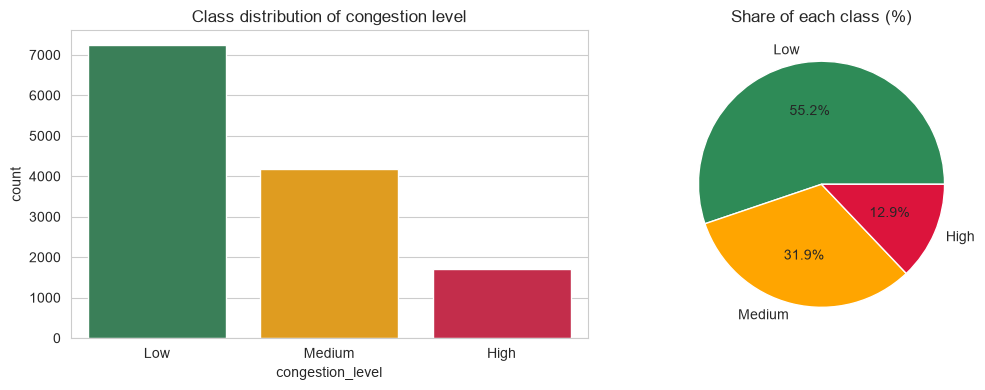

In [5]:
fig, ax = plt.subplots(1,2, figsize=(11,4))
order=["Low","Medium","High"]
sns.countplot(x="congestion_level", data=df, order=order, palette=["seagreen","orange","crimson"], ax=ax[0])
ax[0].set_title("Class distribution of congestion level")
df["congestion_level"].value_counts(normalize=True)[order].mul(100).round(1).plot.pie(autopct="%1.1f%%", ax=ax[1], colors=["seagreen","orange","crimson"])
ax[1].set_ylabel(""); ax[1].set_title("Share of each class (%)")
plt.tight_layout(); plt.show()

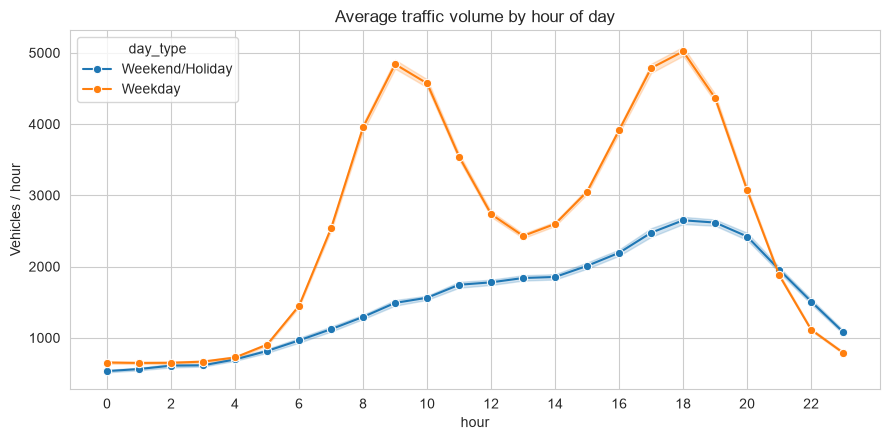

In [6]:
df["day_type"] = np.where((df.is_weekend==1)|(df.is_holiday==1), "Weekend/Holiday", "Weekday")
fig, ax = plt.subplots(figsize=(9,4.5))
sns.lineplot(data=df, x="hour", y="traffic_volume", hue="day_type", marker="o", ax=ax)
ax.set_title("Average traffic volume by hour of day"); ax.set_ylabel("Vehicles / hour"); ax.set_xticks(range(0,24,2))
plt.tight_layout(); plt.show()

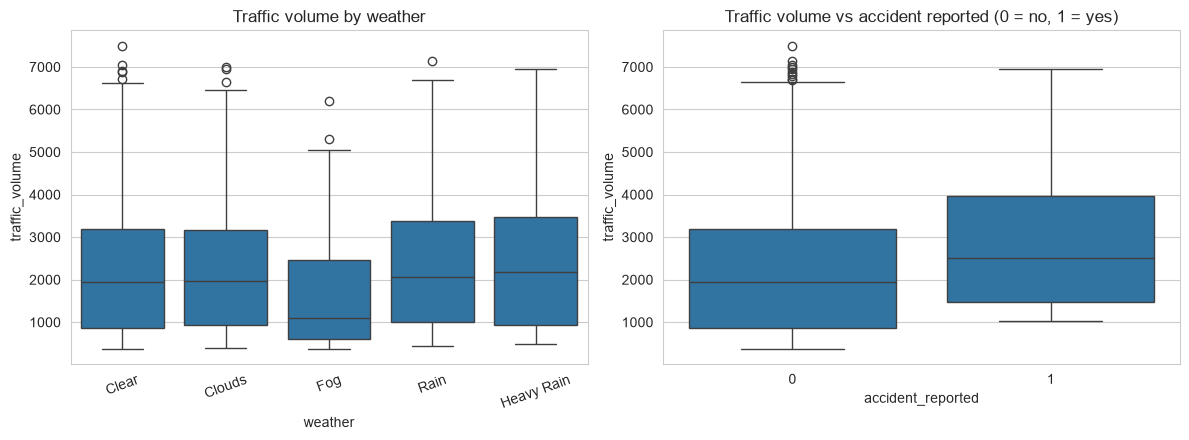

In [7]:
fig, ax = plt.subplots(1,2, figsize=(12,4.5))
sns.boxplot(data=df, x="weather", y="traffic_volume", order=["Clear","Clouds","Fog","Rain","Heavy Rain"], ax=ax[0])
ax[0].set_title("Traffic volume by weather"); ax[0].tick_params(axis="x", rotation=20)
sns.boxplot(data=df, x="accident_reported", y="traffic_volume", ax=ax[1])
ax[1].set_title("Traffic volume vs accident reported (0 = no, 1 = yes)")
plt.tight_layout(); plt.show()

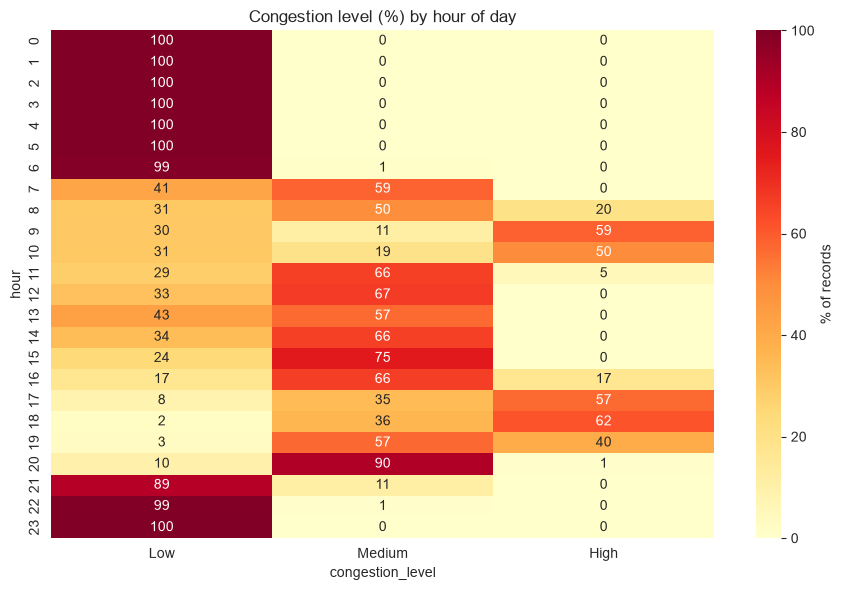

In [8]:
pivot = pd.crosstab(df["hour"], df["congestion_level"], normalize="index")[order]*100
plt.figure(figsize=(9,6)); sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label":"% of records"})
plt.title("Congestion level (%) by hour of day"); plt.tight_layout(); plt.show()

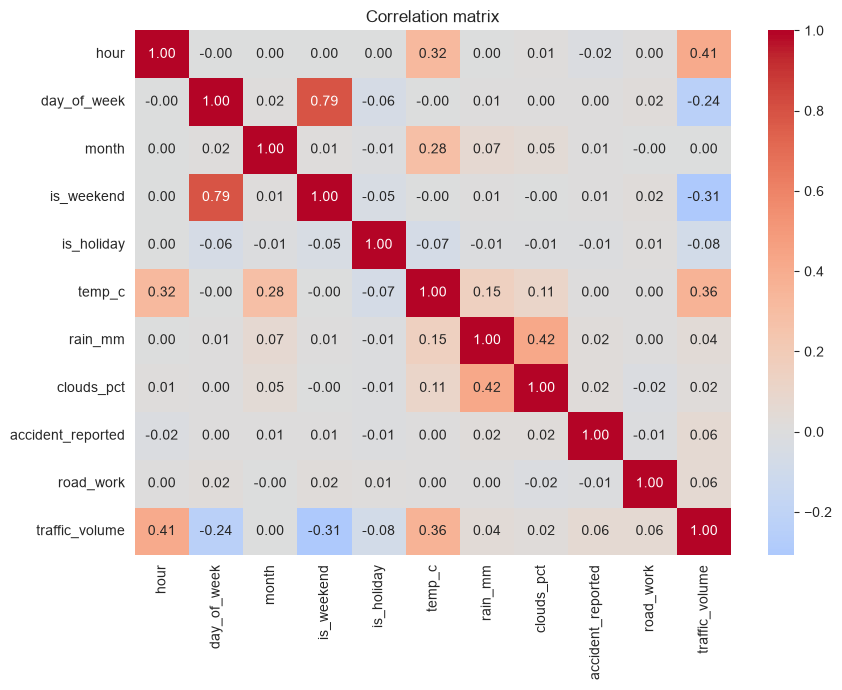

In [9]:
num_cols_eda = ["hour","day_of_week","month","is_weekend","is_holiday","temp_c","rain_mm","clouds_pct","accident_reported","road_work","traffic_volume"]
plt.figure(figsize=(9,7)); sns.heatmap(df[num_cols_eda].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.tight_layout(); plt.show()

### EDA findings & challenges
- **Clear rush-hour pattern:** weekdays show two peaks (~9 AM and ~6 PM); weekends/holidays show a flatter evening peak. *Time of day is the strongest driver of congestion.*
- **Weather matters moderately:** rain and heavy rain raise median volume, fog slightly lowers it (drivers slow down / fewer trips). **Accidents** and **road work** push volume up (queue build-up).
- **Class imbalance:** ~55% Low, ~32% Medium, ~13% High → accuracy alone is misleading; we monitor per-class precision/recall/F1 (especially `High`).
- **Non-linear time effect:** `hour` has almost no *linear* correlation with volume (peaks in the middle of the day), so linear models need engineered cyclic features (`hour_sin`, `hour_cos`).
- **Missing values** in `temp_c`, `rain_mm`, `clouds_pct`, `weather` (1–2% each) must be handled.
- **Leakage warning:** `congestion_level` is derived from `traffic_volume`, so `traffic_volume` must **not** be used as a feature for classification.

## 1.4 Data Preprocessing

In [10]:
print("Missing values BEFORE handling:")
print(df.isna().sum()[df.isna().sum()>0])

Missing values BEFORE handling:
temp_c        262
rain_mm       196
clouds_pct    131
weather       262
dtype: int64


In [11]:
# Feature engineering: cyclic encoding of hour (23:00 is close to 00:00) + peak-hour flag
def add_features(d):
    d = d.copy()
    d["hour_sin"] = np.sin(2*np.pi*d["hour"]/24)
    d["hour_cos"] = np.cos(2*np.pi*d["hour"]/24)
    d["is_peak_hour"] = d["hour"].isin([8,9,10,17,18,19]).astype(int)
    return d

df_fe = add_features(df)
num_features = ["hour","hour_sin","hour_cos","is_peak_hour","day_of_week","month","is_weekend","is_holiday",
                "temp_c","rain_mm","clouds_pct","accident_reported","road_work"]
cat_features = ["weather"]
X = df_fe[num_features + cat_features]
y_class = df_fe["congestion_level"]
y_reg = df_fe["traffic_volume"]
print(X.shape)

(13128, 14)


**Preprocessing pipeline (fit on training data only, to avoid leakage):**
- *Missing values:* numeric → **median** imputation; categorical (`weather`) → **most-frequent** imputation
- *Categorical → numeric:* **one-hot encoding** of `weather`
- *Scaling:* **StandardScaler** on numeric features (needed by Logistic Regression, KNN, Linear Regression)

In [12]:
preprocessor = ColumnTransformer([
    ("num", __import__("sklearn.pipeline", fromlist=["Pipeline"]).Pipeline([
        ("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_features),
    ("cat", __import__("sklearn.pipeline", fromlist=["Pipeline"]).Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_features),
])

## 1.5 Train/Test Split (80% / 20%, stratified)

In [13]:
X_train, X_test, yc_train, yc_test, yr_train, yr_test = train_test_split(
    X, y_class, y_reg, test_size=0.2, random_state=RS, stratify=y_class)

X_train_p = preprocessor.fit_transform(X_train)
X_test_p  = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()
print("Train:", X_train_p.shape, "| Test:", X_test_p.shape)
print("Missing values AFTER preprocessing:", int(np.isnan(X_train_p).sum()))
print("Train class share:\n", yc_train.value_counts(normalize=True).round(3))

Train: (10502, 18) | Test: (2626, 18)
Missing values AFTER preprocessing: 0
Train class share:
 congestion_level
Low       0.552
Medium    0.319
High      0.129
Name: proportion, dtype: float64


---
# PART 2 — Model Implementation & Evaluation

## 2.1 Model Implementation & Training (classification)

In [14]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RS),
    "Decision Tree":       DecisionTreeClassifier(max_depth=8, random_state=RS),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=RS, n_jobs=-1),
    "k-NN":                KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes":         GaussianNB(),
}
for name, m in models.items():
    m.fit(X_train_p, yc_train)
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Decision Tree
Trained: Random Forest
Trained: k-NN
Trained: Naive Bayes


## 2.2 Model Evaluation — accuracy, precision, recall, F1

In [15]:
rows=[]
preds={}
for name, m in models.items():
    p = m.predict(X_test_p); preds[name]=p
    rows.append({"Model":name,
                 "Accuracy":accuracy_score(yc_test,p),
                 "Precision (macro)":precision_score(yc_test,p,average="macro"),
                 "Recall (macro)":recall_score(yc_test,p,average="macro"),
                 "F1 (macro)":f1_score(yc_test,p,average="macro")})
results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,
Logistic Regression,0.8766,0.8430,0.8522,0.8438
Decision Tree,0.9113,0.8731,0.8952,0.8832
Random Forest,0.9025,0.8614,0.8696,0.8654
k-NN,0.8781,0.8358,0.8542,0.8432
Naive Bayes,0.4501,0.5038,0.5408,0.4020


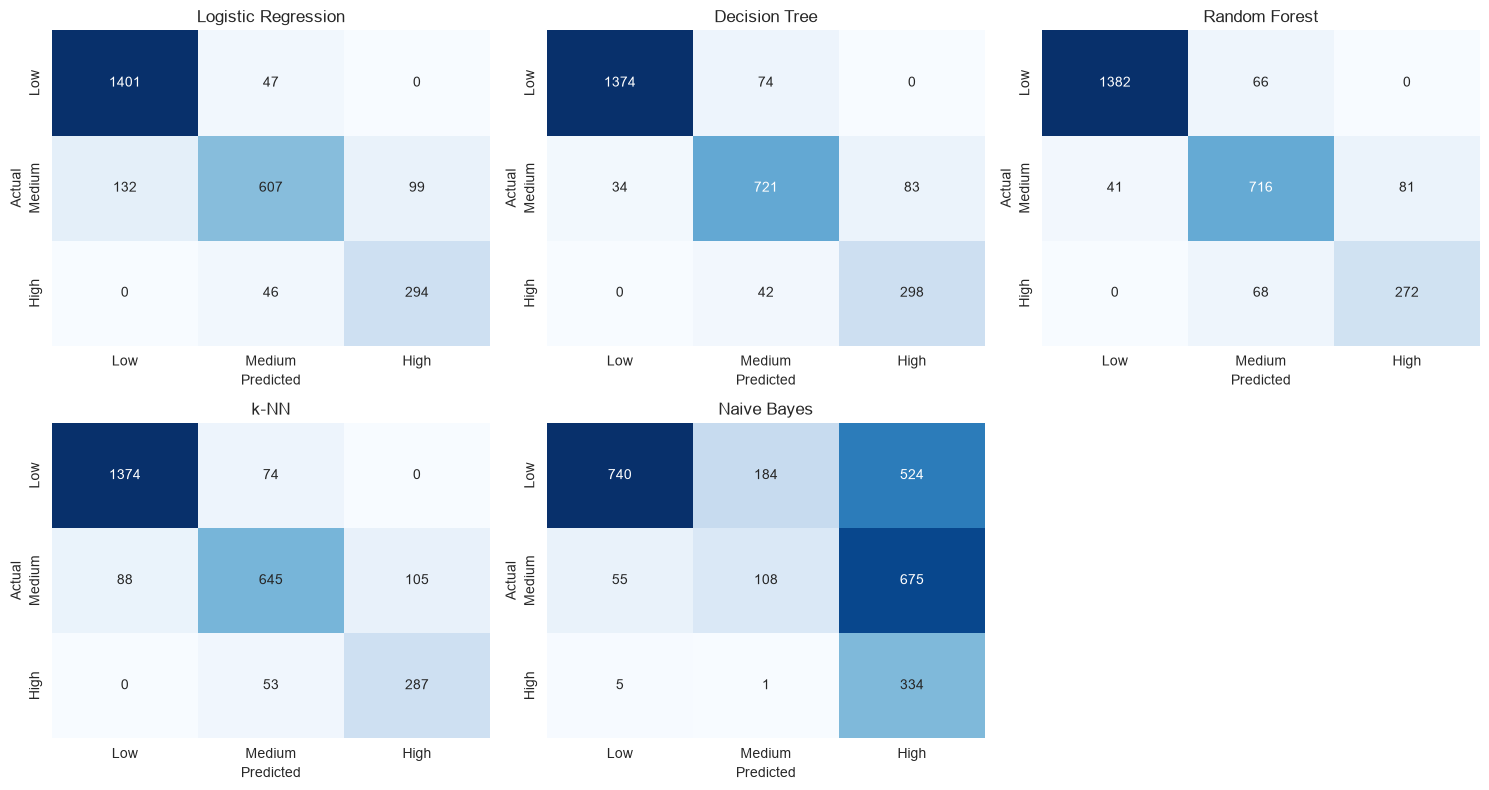

In [16]:
# Confusion matrices
labels=["Low","Medium","High"]
fig, axes = plt.subplots(2,3, figsize=(15,8)); axes=axes.ravel()
for ax,(name,p) in zip(axes, preds.items()):
    sns.heatmap(confusion_matrix(yc_test,p,labels=labels), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
axes[-1].axis("off"); plt.tight_layout(); plt.show()

In [17]:
for name,p in preds.items():
    print("="*60); print(name); print("="*60)
    print(classification_report(yc_test, p, labels=labels))

Logistic Regression
              precision    recall  f1-score   support

         Low       0.91      0.97      0.94      1448
      Medium       0.87      0.72      0.79       838
        High       0.75      0.86      0.80       340

    accuracy                           0.88      2626
   macro avg       0.84      0.85      0.84      2626
weighted avg       0.88      0.88      0.87      2626

Decision Tree
              precision    recall  f1-score   support

         Low       0.98      0.95      0.96      1448
      Medium       0.86      0.86      0.86       838
        High       0.78      0.88      0.83       340

    accuracy                           0.91      2626
   macro avg       0.87      0.90      0.88      2626
weighted avg       0.91      0.91      0.91      2626

Random Forest
              precision    recall  f1-score   support

         Low       0.97      0.95      0.96      1448
      Medium       0.84      0.85      0.85       838
        High       0.77    

## 2.3 Regression model — Linear Regression (traffic volume)

MSE : 471,646.3
RMSE: 686.8 vehicles/hour
MAE : 566.7 vehicles/hour
R²  : 0.7724


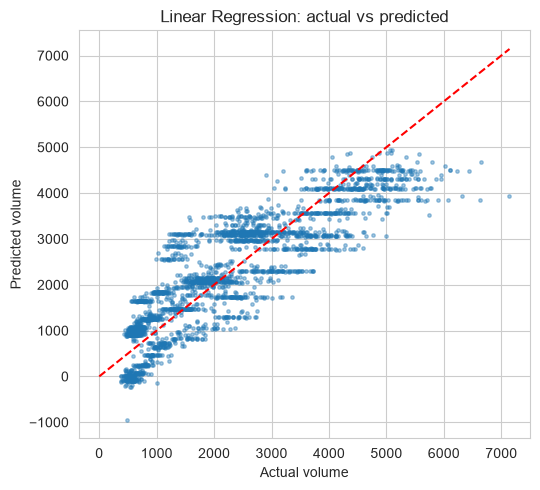

In [18]:
lin = LinearRegression().fit(X_train_p, yr_train)
yr_pred = lin.predict(X_test_p)
mse = mean_squared_error(yr_test, yr_pred)
print(f"MSE : {mse:,.1f}")
print(f"RMSE: {np.sqrt(mse):,.1f} vehicles/hour")
print(f"MAE : {mean_absolute_error(yr_test, yr_pred):,.1f} vehicles/hour")
print(f"R²  : {r2_score(yr_test, yr_pred):.4f}")
plt.figure(figsize=(5.5,5)); plt.scatter(yr_test, yr_pred, s=6, alpha=.4)
lim=[0, max(yr_test.max(), yr_pred.max())]; plt.plot(lim,lim,"r--"); plt.xlabel("Actual volume"); plt.ylabel("Predicted volume")
plt.title("Linear Regression: actual vs predicted"); plt.tight_layout(); plt.show()

**Observation:** Linear Regression explains only part of the variance because traffic volume is a *non-linear* (double-peak) function of the hour. This motivates the tree-based models and the hyperparameter tuning below.

## 2.4 Hyperparameter Tuning — GridSearchCV (Random Forest)

In [19]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [8, 12, None],
    "min_samples_leaf": [1, 3, 5],
    "class_weight": [None, "balanced"],
}
grid = GridSearchCV(RandomForestClassifier(random_state=RS, n_jobs=-1), param_grid,
                    cv=5, scoring="f1_macro", n_jobs=-1)
grid.fit(X_train_p, yc_train)
print("Best parameters :", grid.best_params_)
print(f"Best CV F1-macro: {grid.best_score_:.4f}")

Best parameters : {'class_weight': None, 'max_depth': 8, 'min_samples_leaf': 1, 'n_estimators': 200}
Best CV F1-macro: 0.8753


In [20]:
rf_tuned = grid.best_estimator_
p_t = rf_tuned.predict(X_test_p)
cmp = pd.DataFrame({
    "Random Forest (default)": [accuracy_score(yc_test, preds["Random Forest"]), f1_score(yc_test, preds["Random Forest"], average="macro")],
    "Random Forest (tuned)":   [accuracy_score(yc_test, p_t), f1_score(yc_test, p_t, average="macro")],
}, index=["Accuracy","F1 (macro)"]).T.round(4)
cmp

,Accuracy,F1 (macro)
Random Forest (default),0.9025,0.8654
Random Forest (tuned),0.9132,0.8824


In [21]:
print(classification_report(yc_test, p_t, labels=labels))

              precision    recall  f1-score   support

         Low       0.97      0.96      0.97      1448
      Medium       0.87      0.86      0.86       838
        High       0.78      0.86      0.82       340

    accuracy                           0.91      2626
   macro avg       0.87      0.89      0.88      2626
weighted avg       0.92      0.91      0.91      2626



## 2.5 Cross-Validation — Stratified 5-Fold (model stability)

In [22]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
from sklearn.pipeline import Pipeline
all_models = dict(models); all_models["Random Forest (tuned)"] = rf_tuned
cv_rows=[]; cv_folds={}
for name, m in all_models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", m)])   # preprocessing re-fit inside every fold
    s = cross_validate(pipe, X, y_class, cv=skf, scoring=["accuracy","f1_macro"], n_jobs=-1)
    cv_folds[name]=s["test_accuracy"]
    cv_rows.append({"Model":name,"CV Accuracy (mean)":s["test_accuracy"].mean(),"CV Accuracy (std)":s["test_accuracy"].std(),
                    "CV F1-macro (mean)":s["test_f1_macro"].mean()})
cv_df = pd.DataFrame(cv_rows).set_index("Model").round(4)
cv_df

,CV Accuracy (mean),CV Accuracy (std),CV F1-macro (mean)
Model,,,
Logistic Regression,0.8776,0.0055,0.8480
Decision Tree,0.9062,0.0054,0.8760
Random Forest,0.9019,0.0041,0.8675
k-NN,0.8688,0.0060,0.8324
Naive Bayes,0.4410,0.0422,0.3951
Random Forest (tuned),0.9068,0.0052,0.8760


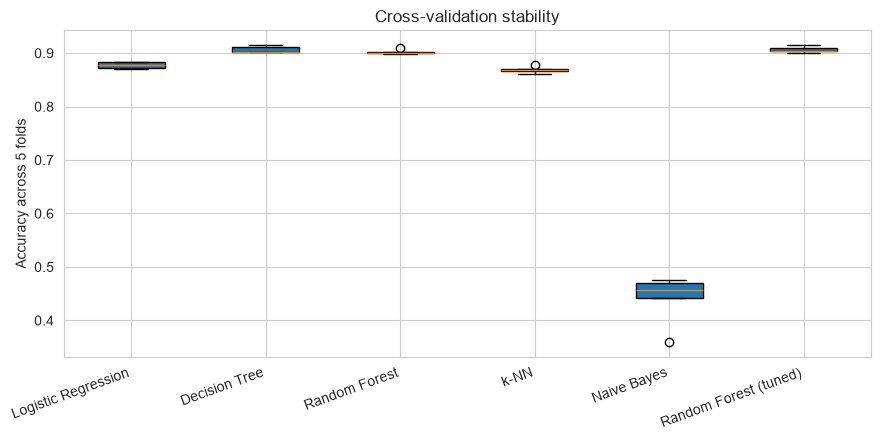

Per-fold accuracy:


,Logistic Regression,Decision Tree,Random Forest,k-NN,Naive Bayes,Random Forest (tuned)
Fold 1,0.8770,0.9021,0.8976,0.8709,0.4760,0.9037
Fold 2,0.8709,0.9109,0.9006,0.8682,0.4703,0.9105
Fold 3,0.8724,0.9021,0.9018,0.8663,0.4570,0.9048
Fold 4,0.8834,0.9013,0.8998,0.8602,0.4415,0.9002
Fold 5,0.8842,0.9143,0.9097,0.8785,0.3600,0.9147


In [31]:
fig, ax = plt.subplots(figsize=(9,4.5))
box = ax.boxplot(list(cv_folds.values()),widths=0.5, patch_artist=True)
ax.set_xticks(range(1, len(cv_folds) + 1))
ax.set_xticklabels(list(cv_folds.keys()), rotation=20, ha="right")
ax.set_ylabel("Accuracy across 5 folds")
ax.set_title("Cross-validation stability"); plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()
print("Per-fold accuracy:"); pd.DataFrame(cv_folds, index=[f"Fold {i}" for i in range(1,6)]).round(4)

## 2.6 Final Model Comparison & Feature Importance

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,
Decision Tree,0.9113,0.8731,0.8952,0.8832
Random Forest (tuned),0.9132,0.8742,0.8921,0.8824
Random Forest,0.9025,0.8614,0.8696,0.8654
Logistic Regression,0.8766,0.8430,0.8522,0.8438
k-NN,0.8781,0.8358,0.8542,0.8432
Naive Bayes,0.4501,0.5038,0.5408,0.4020


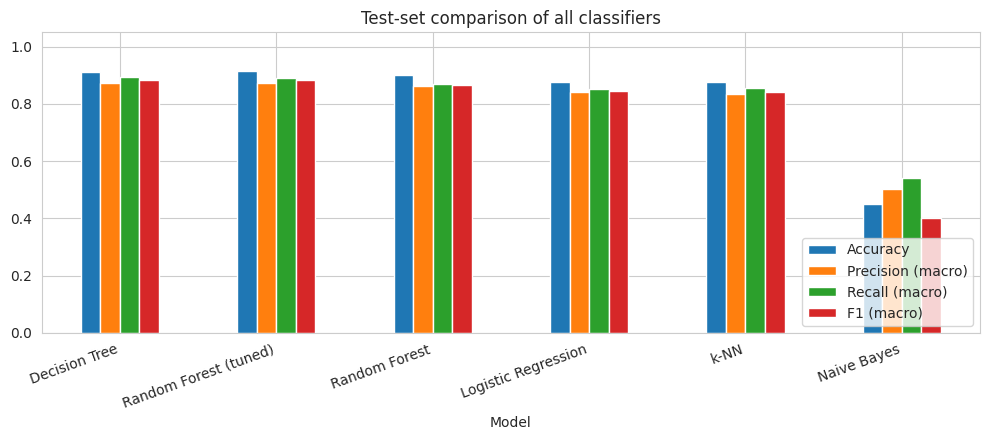

In [ ]:
final = results.copy()
final.loc["Random Forest (tuned)"] = [accuracy_score(yc_test,p_t), precision_score(yc_test,p_t,average="macro"),
                                      recall_score(yc_test,p_t,average="macro"), f1_score(yc_test,p_t,average="macro")]
final = final.round(4).sort_values("F1 (macro)", ascending=False)
display(final)
final.plot(kind="bar", figsize=(10,4.5)); plt.ylim(0,1.05); plt.xticks(rotation=20, ha="right"); plt.title("Test-set comparison of all classifiers")
plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

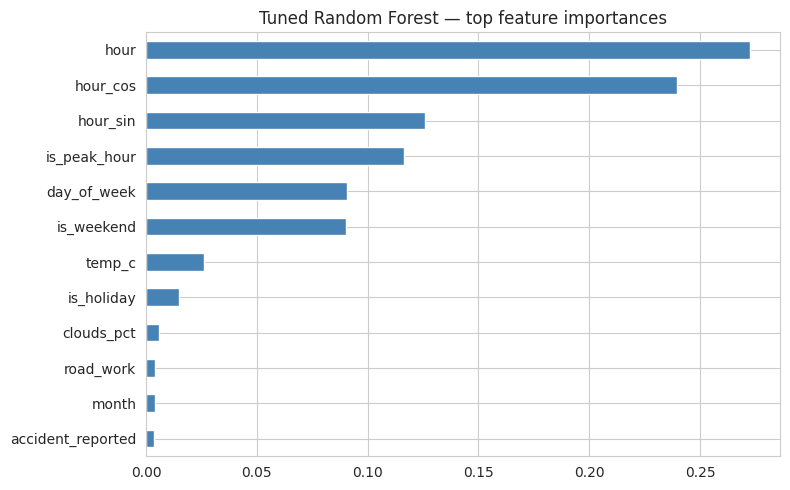

In [ ]:
imp = pd.Series(rf_tuned.feature_importances_, index=[f.split("__")[1] for f in feature_names]).sort_values()
imp.tail(12).plot(kind="barh", figsize=(8,5), color="steelblue"); plt.title("Tuned Random Forest — top feature importances")
plt.tight_layout(); plt.show()

## 2.7 Save trained models (for the Streamlit app)

In [ ]:
import os; os.makedirs("models", exist_ok=True)
joblib.dump(preprocessor, "preprocessor.joblib")
joblib.dump(models["Logistic Regression"], "logistic_regression.joblib")
joblib.dump(models["Decision Tree"], "decision_tree.joblib")
joblib.dump(rf_tuned, "random_forest.joblib")
joblib.dump(models["k-NN"], "knn.joblib")
joblib.dump(models["Naive Bayes"], "naive_bayes.joblib")
joblib.dump(lin, "linear_regression.joblib")
meta = {"classes": list(models["Logistic Regression"].classes_), "num_features": num_features, "cat_features": cat_features,
        "test_results": final.to_dict(), "best_params": grid.best_params_,
        "reg": {"rmse": float(np.sqrt(mse)), "r2": float(r2_score(yr_test, yr_pred))}}
joblib.dump(meta, "meta.joblib")
print(sorted(os.listdir("models")))

['decision_tree.joblib', 'knn.joblib', 'linear_regression.joblib', 'logistic_regression.joblib', 'meta.joblib', 'naive_bayes.joblib', 'preprocessor.joblib', 'random_forest.joblib']
